# Topology ToolKit: understanding scalar fields

A guided introduction to [Topology ToolKit (TTK)](https://topology-tool-kit.github.io/), with explanations, small experiments, and a real TTK pipeline to run in ParaView's Python environment.

**Run with the TDA (conda) kernel.** Sections 1–5 use NumPy, SciPy, and Matplotlib to teach the ideas. They are educational implementations, not TTK output. Section 6 exports a dataset and supplies an actual TTK/ParaView script. The external TTK/ParaView pipeline has now been executed successfully on this Mac, and the desktop app has been verified with the full TTK plugin. Use the launchers described in section 6.

You will learn what scalar fields, critical points, sublevel sets, persistence, merge trees, and Morse–Smale segmentation describe. Every continuous color plot includes a scale.

## 1. Where TTK fits

TTK supplies algorithms for topology and scientific visualization, with ParaView integration and Python/C++ interfaces. Its tools include persistence diagrams, merge and contour trees, Reeb graphs, Morse–Smale complexes, simplification, and comparisons between datasets. It also supports point-cloud analysis. [Official feature overview](https://topology-tool-kit.github.io/)

Our previous notebook grew connections between points using **distance**. Here we start with a connected domain and one **scalar value** at each location. Imagine temperature on a plate or elevation on a terrain. A threshold now selects locations whose values are low enough. Birth/death values are in the scalar's units, rather than necessarily distance units.

| Object | Concrete example | Question |
|---|---|---|
| Domain | A 2D grid or a triangulated surface | Which locations are neighbors? |
| Scalar field | One elevation value at every vertex | What is high or low? |
| Sublevel set | Locations with elevation ≤ h | Which flooded regions are connected at water level h? |
| Level set | Locations with elevation = h | What do contours at this height look like? |

The domain and adjacency matter. Treating `(x, y, value)` as a cloud for Ripser answers a different question from filtering a fixed grid by its values.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label, generate_binary_structure
import shutil, subprocess, os

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
# Resolve paths whether VS Code starts in this folder or the Classes workspace.
project = Path.cwd()
if (project / "Senior-Fall/TDA_Research").is_dir():
    project = project / "Senior-Fall/TDA_Research"
artifact_dir = project / "ttk_assets"
artifact_dir.mkdir(exist_ok=True)
print("Output folder:", artifact_dir)

Output folder: /Users/derickshi/Documents/Classes/Senior-Fall/TDA_Research/ttk_assets


### A terrain with two depressions

The field below is synthetic and has arbitrary scalar units. Its coordinates describe position; color and surface height describe the scalar value. Low regions will enter a sublevel filtration first.

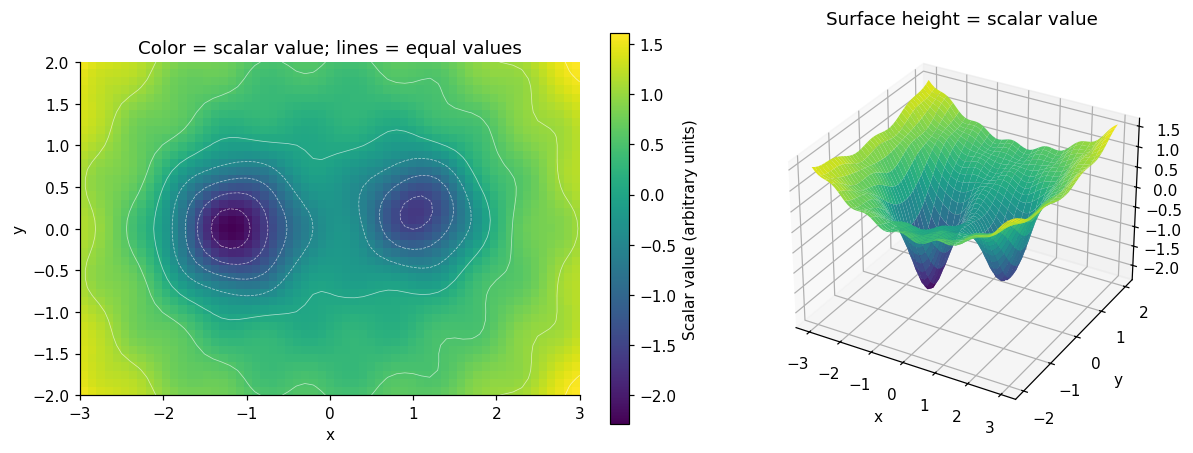

In [2]:
x = np.linspace(-3, 3, 61)
y = np.linspace(-2, 2, 41)
X, Y = np.meshgrid(x, y)
field = (0.12 * (X**2 + Y**2)
         - 2.4 * np.exp(-((X + 1.2)**2 + Y**2) / 0.55)
         - 1.8 * np.exp(-((X - 1.1)**2 + (Y - 0.2)**2) / 0.45)
         + 0.08 * np.sin(6 * X) * np.cos(5 * Y))
fig = plt.figure(figsize=(11, 4), layout="constrained")
a = fig.add_subplot(121)
im = a.imshow(field, origin="lower", extent=[x[0], x[-1], y[0], y[-1]],
              cmap="viridis", aspect="equal")
a.contour(X, Y, field, levels=8, colors="white", linewidths=0.5, alpha=0.6)
a.set(title="Color = scalar value; lines = equal values", xlabel="x", ylabel="y")
fig.colorbar(im, ax=a, label="Scalar value (arbitrary units)")
b = fig.add_subplot(122, projection="3d")
b.plot_surface(X, Y, field, cmap="viridis", vmin=field.min(), vmax=field.max())
b.set(xlabel="x", ylabel="y", zlabel="", title="Surface height = scalar value")
plt.show()

## 2. Flood the landscape: sublevel sets

At threshold h, include vertices where `field <= h` and edges between included neighbors. Components appear near minima and merge as water crosses passes. A **saddle** is a pass-like critical point in a smooth 2D landscape: the field rises in some directions and falls in others. Maxima are peaks; minima are pits.

This demonstration uses four-neighbor grid connectivity. It illustrates components only; a triangulation or another connectivity convention can give different discrete events. TTK uses its input domain and triangulation conventions, so these counts are not a promised numerical match to TTK.

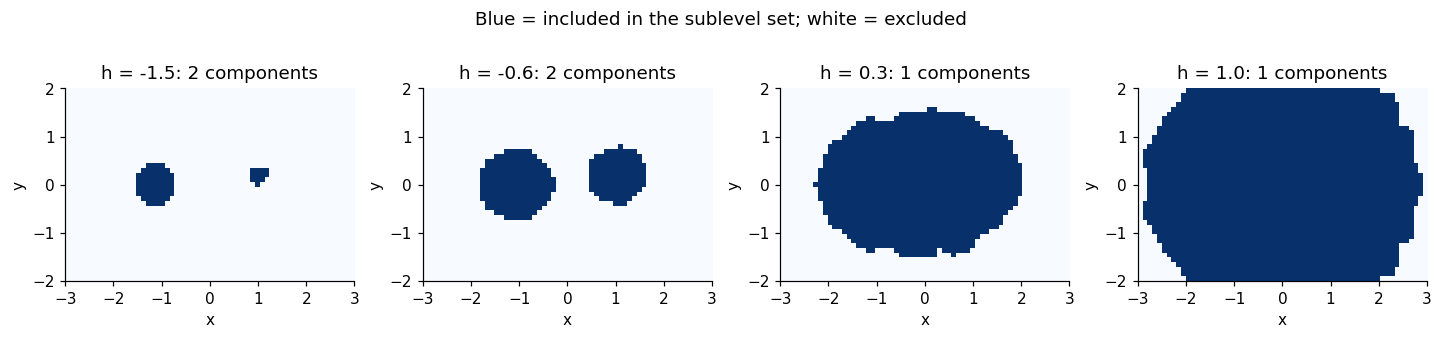

In [3]:
thresholds = [-1.5, -0.6, 0.3, 1.0]
fig, axes = plt.subplots(1, 4, figsize=(13, 3), layout="constrained")
connectivity = generate_binary_structure(2, 1)
for ax, h in zip(axes, thresholds):
    mask = field <= h
    components, count = label(mask, structure=connectivity)
    ax.imshow(mask, origin="lower", extent=[x[0], x[-1], y[0], y[-1]],
              cmap="Blues", vmin=0, vmax=1)
    ax.set(title=f"h = {h:.1f}: {count} components", xlabel="x", ylabel="y")
fig.suptitle("Blue = included in the sublevel set; white = excluded")
plt.show()

## 3. Compute H0 persistence by hand on a small path

Use a line of vertices with scalar values `[0, 3, 1, 4, 0.5]`. Adjacent vertices are connected when both have appeared. The edge's entry value is the larger endpoint value. This is a lower-star filtration of a path.

Three components are born at values 0, 0.5, and 1. At threshold 3, the component born at 1 meets the older component born at 0. The older component survives (the **elder rule**), giving pair `(1, 3)`. At threshold 4, the component born at 0.5 joins it, giving `(0.5, 4)`. One component survives forever in ordinary H0 persistence.

The following small union-find implementation records those events. It discards zero-length intervals and uses vertex index to break equal-value ties. Its scope is H0 on a path; it is not a replacement for TTK's general algorithms.

Finite birth/death pairs: [[1.0, 3.0], [0.5, 4.0]]
Essential pair: (0.0, inf)


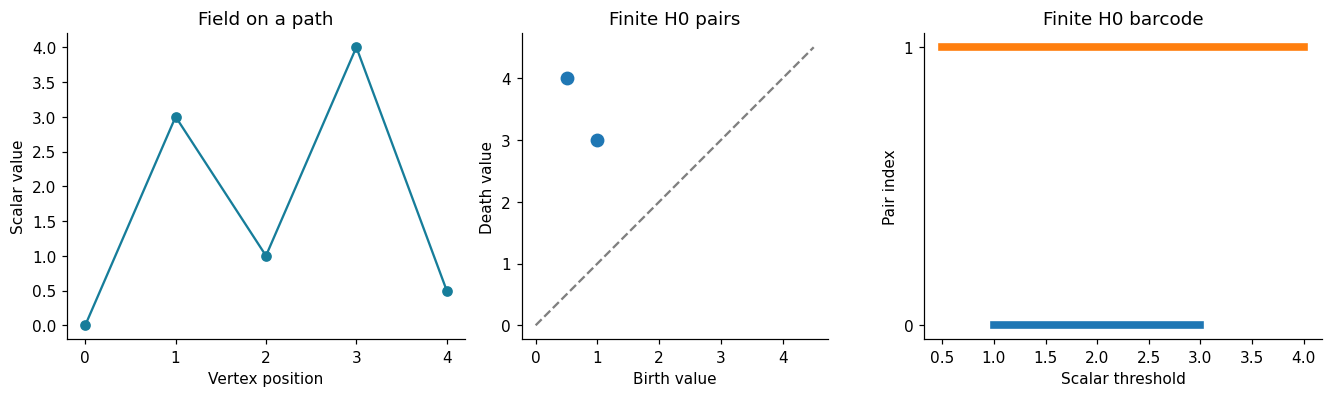

In [4]:
def path_h0(values):
    values = np.asarray(values, dtype=float)
    parent = np.arange(len(values))
    active = np.zeros(len(values), dtype=bool)
    pairs = []
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i in np.lexsort((np.arange(len(values)), values)):
        active[i] = True
        for j in (i - 1, i + 1):
            if 0 <= j < len(values) and active[j]:
                a, b = find(i), find(j)
                if a == b:
                    continue
                old, young = sorted((a, b), key=lambda r: (values[r], r))
                if values[i] > values[young]:
                    pairs.append((values[young], values[i]))
                parent[young] = old
    return np.asarray(pairs, dtype=float).reshape(-1, 2), float(values.min())

signal = np.array([0, 3, 1, 4, 0.5])
pairs, essential_birth = path_h0(signal)
np.testing.assert_allclose(pairs, [[1, 3], [0.5, 4]])
print("Finite birth/death pairs:", pairs.tolist())
print("Essential pair:", (essential_birth, np.inf))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
axes[0].plot(signal, "o-", color="#167d9a")
axes[0].set(xlabel="Vertex position", ylabel="Scalar value", title="Field on a path")
axes[1].plot([0, 4.5], [0, 4.5], "--", color="gray")
axes[1].scatter(pairs[:, 0], pairs[:, 1], s=65)
axes[1].set(xlabel="Birth value", ylabel="Death value", title="Finite H0 pairs", aspect="equal")
for row, (birth, death) in enumerate(pairs):
    axes[2].plot([birth, death], [row, row], lw=5)
axes[2].set(xlabel="Scalar threshold", ylabel="Pair index", title="Finite H0 barcode", yticks=[0, 1])
plt.show()

### Merge trees, contour trees, and Reeb graphs

A **join tree** summarizes how sublevel components are born and merge. In our path example, follow three branches born at 0, 0.5, and 1; the last merges into the oldest at 3, and the remaining branch merges at 4. A **split tree** follows superlevel components instead, starting from high regions.

A **Reeb graph** collapses each connected component of a level set to a point. It records changes in contour connectivity; a **contour tree** is the tree form used for suitable domains. A merge tree records one direction of component evolution and does not encode all homology dimensions. These summaries can locate events in the original domain, which is useful for interpreting simulations.

**Check:** in `(0.5, 4)`, persistence is 3.5 scalar units. It is not the horizontal length of a basin in the domain.

## 4. Persistence thresholds and simplification

A persistence curve can show how many pairs remain above each persistence cutoff. The next plot counts **finite H0 pairs on our path**. It is different from counting components alive at one scalar threshold.

Selecting high-persistence pairs is one step in a simplification workflow. Changing the scalar field to remove unwanted topological features is a further operation. TTK provides topological simplification with selected constraints; merely hiding diagram points does not alter the original field. Small features can be meaningful, so choose cutoffs with the application's units and question in mind.

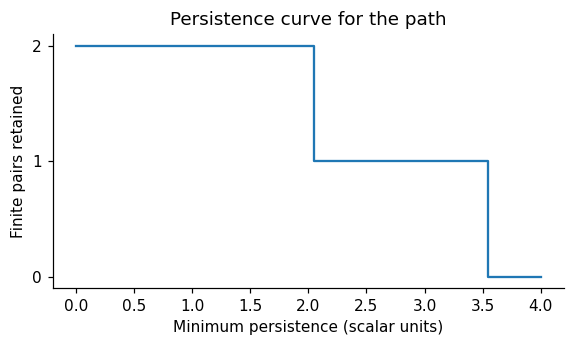

Pairs selected at cutoff 2.5: [[0.5, 4.0]]
This selection does not modify signal: [0.0, 3.0, 1.0, 4.0, 0.5]


In [5]:
lifetimes = pairs[:, 1] - pairs[:, 0]
cutoffs = np.linspace(0, 4, 81)
remaining = (lifetimes[:, None] >= cutoffs).sum(axis=0)
fig, ax = plt.subplots(figsize=(6, 3))
ax.step(cutoffs, remaining, where="post")
ax.set(xlabel="Minimum persistence (scalar units)", ylabel="Finite pairs retained",
       title="Persistence curve for the path", yticks=[0, 1, 2])
plt.show()
keep = lifetimes >= 2.5
print("Pairs selected at cutoff 2.5:", pairs[keep].tolist())
print("This selection does not modify signal:", signal.tolist())

## 5. What would a Morse–Smale complex add?

Think of following a landscape downhill toward a minimum and uphill toward a maximum. A Morse–Smale complex organizes the domain into regions according to these gradient-flow destinations, together with critical points and separating structures. It can support segmentation: for example, assigning regions of a scalar field to significant extrema. On sampled data, TTK computes a discrete version of this structure.

This notebook has visualized scalar values and components; it has **not** computed a Morse–Smale complex in NumPy. The optional TTK script below computes one on our generated field.

| Task | Possible TTK output | Interpretation |
|---|---|---|
| Locate extrema and passes | Critical points | Locations where topology may change |
| Rank topological events | Persistence diagram / curve | Scalar separation of paired events |
| Summarize connectivity | Merge or contour tree | How regions or contours connect across levels |
| Partition a field | Morse–Smale segmentation | Regions organized by gradient flow |
| Compare many fields | Distances or summaries of diagrams / trees | Features for exploration, clustering, or ML |

For ML, a segmentation is not automatically a feature matrix. Decide what one labeled example is, then extract consistent summaries or use a model appropriate for structured objects. Persistence images from the earlier notebook are one possible diagram representation. Scalar-field and distance-filtration persistence can have different meanings and units.

## 6. Run the real TTK pipeline

The next cell exports our field to `ttk_assets/landscape.vti`, a VTK image-data file with a point scalar named `height`. This export only uses Python's XML tools. It keeps geometry and scalar values separate.

The companion [ttk_pipeline.py](ttk_assets/ttk_pipeline.py) reads the field, computes a TTK persistence diagram and a Morse–Smale complex, and saves VTK outputs. Its API calls follow the official [Morse persistence example](https://topology-tool-kit.github.io/examples/morsePersistence/). The example also demonstrates optional persistence-guided simplification; our small pipeline operates directly on the input field.

TTK may encode global or essential pairs differently from the ordinary H0 convention in our path demonstration. Inspect pair types and output arrays before comparing values.

In [6]:
import xml.etree.ElementTree as ET
extent = f"0 {len(x)-1} 0 {len(y)-1} 0 0"
root = ET.Element("VTKFile", type="ImageData", version="0.1", byte_order="LittleEndian")
grid = ET.SubElement(root, "ImageData", WholeExtent=extent,
    Origin=f"{x[0]} {y[0]} 0", Spacing=f"{x[1]-x[0]} {y[1]-y[0]} 1")
piece = ET.SubElement(grid, "Piece", Extent=extent)
point_data = ET.SubElement(piece, "PointData", Scalars="height")
array = ET.SubElement(point_data, "DataArray", type="Float64", Name="height", format="ascii")
# VTK image data lists x fastest, matching C-order flattening of field[y, x].
array.text = " ".join(format(v, ".17g") for v in field.ravel())
ET.SubElement(piece, "CellData")
input_path = artifact_dir / "landscape.vti"
ET.ElementTree(root).write(input_path, encoding="utf-8", xml_declaration=True)
print("Exported", field.shape, "field to", input_path)

Exported (41, 61) field to /Users/derickshi/Documents/Classes/Senior-Fall/TDA_Research/ttk_assets/landscape.vti


### Launching on this Mac

The runtime is configured and verified. Double-click [Open ParaView.command](Open%20ParaView.command) in Finder to open the desktop app with the TTK plugin and saved terrain demonstration.

To recompute the four output files from the `TDA_Research` folder:

```sh
sh ttk_assets/run_ttk.sh
```

The launcher uses the packages under `~/ttk-binary`, Homebrew Python 3.13, and compatible Graphviz libraries installed separately under `~/ttk-binary/compat`. It sets the necessary paths for that process. No Conda activation or `.zshrc` changes are needed. Keep `~/ttk-binary` in place.

In ParaView, select `landscape.vti`, then use **Filters → Search** to add **TTK PersistenceDiagram** or **TTK MorseSmaleComplex** with scalar field `height`. The saved demonstration already contains the Morse–Smale filter.

For a different machine, consult TTK's [installation page](https://topology-tool-kit.github.io/installation.html); the published Conda command did not provide an Apple Silicon package during this setup. See [runtime notes](ttk_assets/RUNTIME_NOTES.md) for this Mac's compatibility settings.


In [ ]:
RUN_TTK = False  # Set True to recompute using this Mac's configured runtime.
if not RUN_TTK:
    print("TTK results already exist in ttk_assets/results. Set RUN_TTK=True to recompute.")
else:
    result = subprocess.run(["sh", str(artifact_dir / "run_ttk.sh")],
        check=True, text=True, capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)


### Reading the TTK outputs

The verified outputs are in `ttk_assets/results`. Open these files in ParaView:

- `diagram.vtu`: persistence pairs and associated arrays. Inspect the `Persistence` and pair metadata; color represents the array selected in ParaView.
- `critical_points.vtp`: points in the original domain. Inspect the critical-point type and scalar value.
- `separatrices.vtp`: one-dimensional separating structures from the Morse–Smale complex.
- `segmentation.vti`: the domain with segmentation arrays. Region IDs are categorical labels; larger IDs do not mean greater importance.

Use ParaView's Spreadsheet View to inspect available arrays. Exact arrays and UI labels can vary with the installed TTK/ParaView version. The external script has been run successfully with this Mac's configured runtime.

## 7. Experiments and next steps

1. Change one well's depth in `field`. Predict how its basin becomes more or less persistent, then inspect the threshold plots.
2. Change `signal` to `[0, 2, 1, 4, 0.5]`. The `(1, 3)` pair should become `(1, 2)`; its persistence decreases.
3. Compare sublevel sets of `field` with sublevel sets of `-field`. The latter explore high regions of the original field.
4. After running TTK, inspect where its critical points lie in the original terrain. Then follow the official simplification example to reduce small features before segmentation.

Source guides: [TTK home](https://topology-tool-kit.github.io/), [installation](https://topology-tool-kit.github.io/installation.html), [example database](https://topology-tool-kit.github.io/examples/), and [Morse persistence pipeline](https://topology-tool-kit.github.io/examples/morsePersistence/).